# An automated mission feasibility report

Every notebook so far has designed, flown, and checked one piece of a mission at a time, with a human (this notebook's author) wiring the pieces together by hand. This notebook is different: it takes a mission described declaratively, in a YAML file, and runs it through dynamics, safety, and budget automatically, producing a single feasibility verdict and a shareable report, with no notebook-specific code standing between the scenario and the answer.

The pipeline behind this, `ios_mission_planner.report`, reuses only closed-form building blocks already validated elsewhere in this project (`hohmann_transfer`, `cw_targeting`, the rocket equation, the full safety suite), so a report generates in seconds, not minutes, and every number in it traces back to a function documented in this book.

In [1]:
from pathlib import Path
from IPython.display import HTML, display

from ios_mission_planner.report.scenario import load_scenario
from ios_mission_planner.report.pipeline import run_feasibility_analysis
from ios_mission_planner.report.render import render_html, render_pdf

SCENARIOS_DIR = Path(".")

## The baseline scenario

`baseline_scenario.yaml` describes the same mission `mission_budget.ipynb` built by hand: a 500 km chief, a 400 km parking deputy, both at 51.6 degrees, a 200 m safety ellipse, a 2-day station-keeping dwell, docking, and a deorbit to 200 km perigee altitude, flown with 1800 s electric propulsion on a 150 kg dry mass. The file also carries the thresholds a verdict is checked against: a maximum collision probability and a maximum wet mass.

In [2]:
scenario = load_scenario(SCENARIOS_DIR / "baseline_scenario.yaml")
result = run_feasibility_analysis(scenario)

print(f"verdict: {result.verdict}")
for issue in result.issues:
    print(f"  - {issue}")
print()
print(f"total delta-v (margined, with reserve): {result.delta_v_total:.3f} m/s")
print(f"propellant mass: {result.propellant_mass_kg:.4f} kg")
print(f"wet mass: {result.wet_mass_kg:.2f} kg (budget: {scenario.verdict_thresholds.max_wet_mass_kg:.1f} kg)")
print(f"Monte Carlo collision probability: {result.collision_probability:.3%} "
      f"(threshold: {scenario.verdict_thresholds.max_collision_probability:.3%})")


verdict: NOT FEASIBLE
  - Monte Carlo collision probability (2.29%) exceeds the threshold (1.00%).

total delta-v (margined, with reserve): 190.950 m/s
propellant mass: 1.6314 kg
wet mass: 151.63 kg (budget: 160.0 kg)
Monte Carlo collision probability: 2.290% (threshold: 1.000%)


Every deterministic safety check passes, by a wide margin, and the propellant budget is a small fraction of the stated wet-mass limit. The verdict comes out **NOT FEASIBLE** anyway, because the Monte Carlo collision probability does not, at roughly 2.3% against a 1% threshold. This is not a bug in the pipeline; it is the same finding `rendezvous_safety_assessment.ipynb` reached by hand: the linear state transition matrix used for the Monte Carlo check amplifies velocity uncertainty into a surprisingly large position spread over an orbit, a risk none of the deterministic margin checks above can see on their own. A feasibility tool that only ever says yes is not actually checking anything; this is the pipeline doing its job.

wrote baseline_report.html (93223 bytes)


wrote baseline_report.pdf



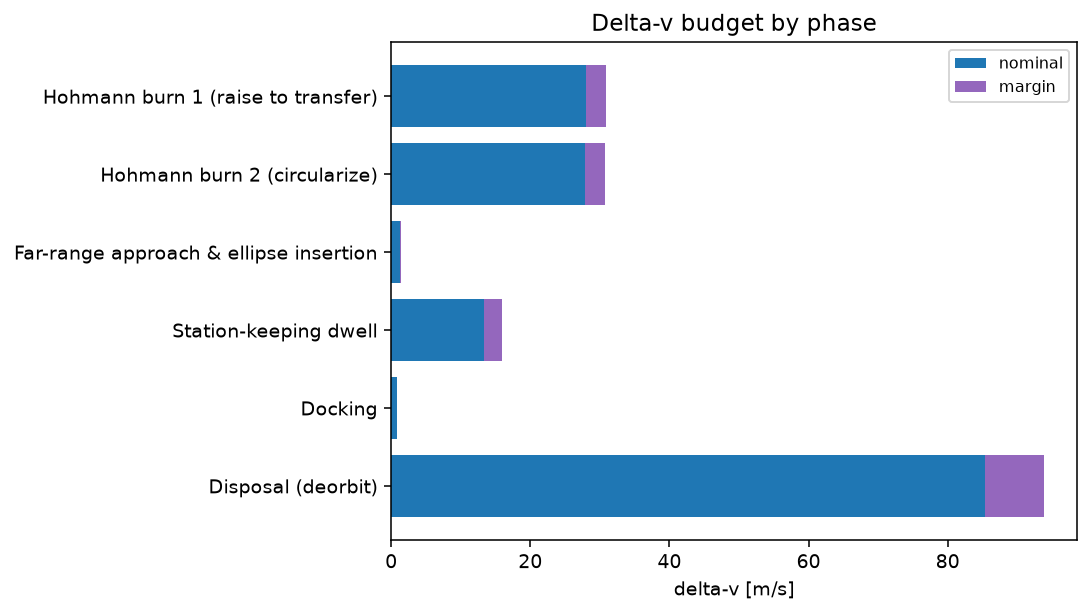
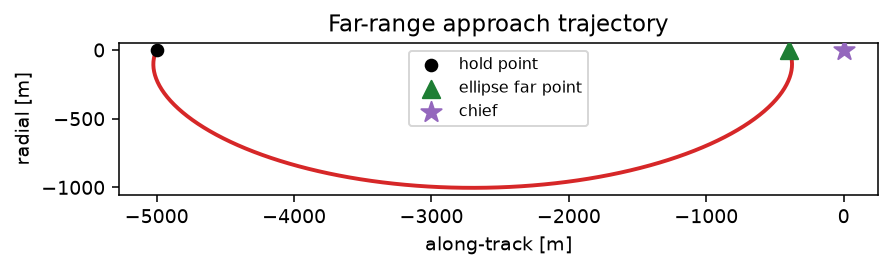

In [3]:
html = render_html(result)
Path("baseline_report.html").write_text(html, encoding="utf-8")
print(f"wrote baseline_report.html ({len(html)} bytes)")

try:
    render_pdf(html, "baseline_report.pdf")
    print("wrote baseline_report.pdf")
except Exception as exc:
    print(f"PDF export skipped: {exc}")

display(HTML(html))

## A scenario that passes: better relative navigation

`improved_nav_scenario.yaml` is identical to the baseline in every respect except one: the assumed relative-navigation uncertainty drops from 10 m to 3 m, standing in for a more precise sensor (a vision-based or lidar relative navigation system, say) rather than a coarser one. Nothing about the trajectory design or the propellant budget changes; only the input to the Monte Carlo check does.

verdict: FEASIBLE
Monte Carlo collision probability: 0.935% (threshold: 1.000%)



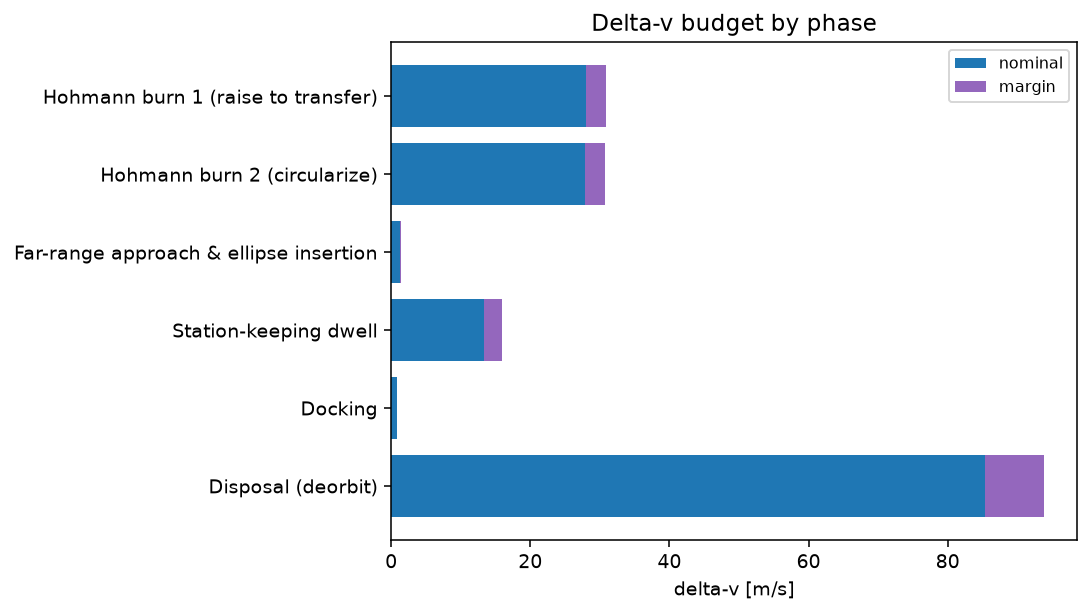
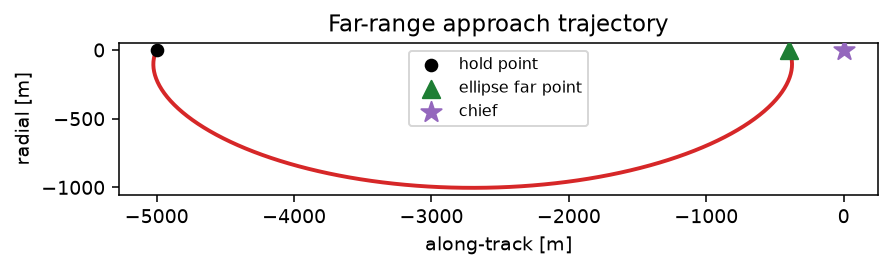

In [4]:
scenario_improved = load_scenario(SCENARIOS_DIR / "improved_nav_scenario.yaml")
result_improved = run_feasibility_analysis(scenario_improved)

print(f"verdict: {result_improved.verdict}")
print(f"Monte Carlo collision probability: {result_improved.collision_probability:.3%} "
      f"(threshold: {scenario_improved.verdict_thresholds.max_collision_probability:.3%})")

html_improved = render_html(result_improved)
Path("improved_nav_report.html").write_text(html_improved, encoding="utf-8")

try:
    render_pdf(html_improved, "improved_nav_report.pdf")
except Exception:
    pass

display(HTML(html_improved))

The same mission, the same budget, the same deterministic safety margins, but a tighter navigation assumption is enough to bring the collision probability under threshold and flip the verdict to feasible. This is exactly the kind of trade a real feasibility study needs to surface: not just whether a mission works, but which assumption it is most sensitive to, and by how much.

## Summary

This turns the tools built so far into a feasibility report that a declarative scenario file produces automatically, by orchestrating the dynamics, safety, and budget tools built in every earlier chapter of this book, rather than by hand-wiring a new notebook for every mission. The pipeline stays deliberately simple in one respect worth stating plainly: every delta-v comes from closed-form methods, not from a fresh nonlinear re-flight of the mission the way `mission_budget.ipynb` itself does, which is why the far-range hop and the ellipse insertion collapse into a single budget line here instead of the two separate, slightly different burns that notebook flies. That is an honest simplification for a tool meant to turn a scenario around in seconds, not a hidden one: the pipeline flags it explicitly whenever it is worth noticing.

What this does not do yet is pick scenarios: nothing here searches over mission parameters for one that passes, or explains why the input it was given has whatever margin it has beyond the explicit checks already built. Turning this from a report generator into a design tool, one that suggests what to change rather than just saying yes or no, is a natural next step this notebook does not take.